# 01 · First Look at the Data

**Goal:** understand what this dataset contains *before* analysing it. Every real data project starts here.

**You will learn to:**
- load a CSV file into a pandas DataFrame
- inspect its size, columns and data types
- convert text into real dates
- measure missing data, overall and per city
- draw your first time-series chart

**How to use this notebook**
- Run a cell with **Shift + Enter**.
- Cells marked **Your code** are for you. Try first, using the hints. If you're stuck for more than ~15 minutes, ask Claude: describe what you tried and what happened.
- Cells marked **Your answer** are for short written answers. Writing down what you observe is half of data science.

## Step 1 · Imports

`pandas` is the main library for working with tables of data. By convention it's imported as `pd`, so you'll see `pd.something` everywhere. `matplotlib` and `seaborn` draw charts.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)  # show all columns when printing a table

## Step 2 · Load the data

`pd.read_csv()` reads a CSV file and returns a **DataFrame**: a table with rows and named columns.

The path starts with `../` because this notebook lives in `notebooks/`, so we go up one folder to reach `data/`.

In [2]:
df = pd.read_csv("../data/raw/city_day.csv")

### Exercise 2.1 · How big is it, and what does it look like?

1. How many rows and columns does `df` have? *Hint:* `df.shape`
2. Show the first 5 rows. *Hint:* `df.head()`
3. Show the last 5 rows, and 5 random rows. *Hint:* `df.tail()`, `df.sample(5)`

Put each in its own line, or use extra cells (the **+ Code** button).

In [3]:
# Your code
df.shape
df.head(5)
df.tail(5),df.sample(5)

(                City        Date  PM2.5   PM10    NO    NO2    NOx    NH3  \
 29526  Visakhapatnam  2020-06-27  15.02  50.94  7.68  25.06  19.54  12.47   
 29527  Visakhapatnam  2020-06-28  24.38  74.09  3.42  26.06  16.53  11.99   
 29528  Visakhapatnam  2020-06-29  22.91  65.73  3.45  29.53  18.33  10.71   
 29529  Visakhapatnam  2020-06-30  16.64  49.97  4.05  29.26  18.80  10.03   
 29530  Visakhapatnam  2020-07-01  15.00  66.00  0.40  26.85  14.05   5.20   
 
          CO    SO2     O3  Benzene  Toluene  Xylene   AQI    AQI_Bucket  
 29526  0.47   8.55  23.30     2.24    12.07    0.73  41.0          Good  
 29527  0.52  12.72  30.14     0.74     2.21    0.38  70.0  Satisfactory  
 29528  0.48   8.42  30.96     0.01     0.01    0.00  68.0  Satisfactory  
 29529  0.52   9.84  28.30     0.00     0.00    0.00  54.0  Satisfactory  
 29530  0.59   2.10  17.05      NaN      NaN     NaN  50.0          Good  ,
             City        Date   PM2.5    PM10     NO    NO2    NOx    NH3  \
 1

**Your answer:** In one sentence, what does *one row* of this table represent?

>29526  Visakhapatnam  2020-06-27  15.02  50.94  7.68  25.06  19.54  12.47  

## Step 3 · Columns and data types

Quick glossary of the columns:

| Column | Meaning |
|---|---|
| `PM2.5`, `PM10` | Fine and coarse particulate matter (µg/m³), the main drivers of smog and health damage |
| `NO`, `NO2`, `NOx` | Nitrogen oxides, mostly from vehicle exhaust |
| `SO2` | Sulphur dioxide, mostly from coal power and industry |
| `CO` | Carbon monoxide, from incomplete burning of fuel |
| `O3` | Ground-level ozone |
| `NH3`, `Benzene`, `Toluene`, `Xylene` | Other pollutants (ammonia and industrial/vehicle chemicals) |
| `AQI` | Air Quality Index, a single 0–500 score summarising the pollutants |
| `AQI_Bucket` | AQI as a category: Good (0–50), Satisfactory (51–100), Moderate (101–200), Poor (201–300), Very Poor (301–400), Severe (401+) |

Every column has a **data type** (dtype): `float64` means decimal numbers, `object` usually means text.

### Exercise 3.1
Run `df.info()`. It shows each column's dtype and how many non-missing values it has.

In [4]:
# Your code
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 29531 entries, 0 to 29530
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   City        29531 non-null  str    
 1   Date        29531 non-null  str    
 2   PM2.5       24933 non-null  float64
 3   PM10        18391 non-null  float64
 4   NO          25949 non-null  float64
 5   NO2         25946 non-null  float64
 6   NOx         25346 non-null  float64
 7   NH3         19203 non-null  float64
 8   CO          27472 non-null  float64
 9   SO2         25677 non-null  float64
 10  O3          25509 non-null  float64
 11  Benzene     23908 non-null  float64
 12  Toluene     21490 non-null  float64
 13  Xylene      11422 non-null  float64
 14  AQI         24850 non-null  float64
 15  AQI_Bucket  24850 non-null  str    
dtypes: float64(13), str(3)
memory usage: 3.6 MB


**Your answer:** Which column has a data type that looks *wrong* for what it contains? Why is that a problem?

>date should be in float dtype

## Step 4 · Converting text into dates

Right now `Date` is just text, like `"2015-01-01"`. Python can't do date maths on text: it can't tell you the month, compare dates, or group by year. `pd.to_datetime()` converts it into a real date type.

### Exercise 4.1
1. Convert the column: `df["Date"] = pd.to_datetime(df["Date"])`
2. Check that its dtype changed. *Hint:* `df["Date"].dtype`
3. Find the earliest and latest date. *Hint:* `.min()` and `.max()`

In [5]:
# Your code
df["Date"] = pd.to_datetime(df["Date"])
df["Date"].dtype
df.min(),df.max()


(City                    Ahmedabad
 Date          2015-01-01 00:00:00
 PM2.5                        0.04
 PM10                         0.01
 NO                           0.02
 NO2                          0.01
 NOx                           0.0
 NH3                          0.01
 CO                            0.0
 SO2                          0.01
 O3                           0.01
 Benzene                       0.0
 Toluene                       0.0
 Xylene                        0.0
 AQI                          13.0
 AQI_Bucket                   Good
 dtype: object,
 City                Visakhapatnam
 Date          2020-07-01 00:00:00
 PM2.5                      949.99
 PM10                       1000.0
 NO                         390.68
 NO2                        362.21
 NOx                        467.63
 NH3                        352.89
 CO                         175.81
 SO2                        193.86
 O3                         257.73
 Benzene                    455.03
 Tol

## Step 5 · Cities

### Exercise 5.1
1. How many different cities are there? *Hint:* `df["City"].nunique()`
2. How many rows does each city have? *Hint:* `df["City"].value_counts()`

In [6]:
# Your code
df["City"].nunique()
df["City"].value_counts()

City
Ahmedabad             2009
Bengaluru             2009
Chennai               2009
Delhi                 2009
Lucknow               2009
Mumbai                2009
Hyderabad             2006
Patna                 1858
Gurugram              1679
Visakhapatnam         1462
Amritsar              1221
Jorapokhar            1169
Jaipur                1114
Thiruvananthapuram    1112
Amaravati              951
Brajrajnagar           938
Talcher                925
Kolkata                814
Guwahati               502
Coimbatore             386
Shillong               310
Chandigarh             304
Bhopal                 289
Ernakulam              162
Kochi                  162
Aizawl                 113
Name: count, dtype: int64

**Your answer:** Do all cities have the same number of rows? What might explain the difference? *(Think about when air-quality monitoring stations were installed.)*

>

## Step 6 · Missing values

Missing values show up as `NaN` ("not a number"). In sensor data they're normal: a sensor was offline, broken, or not installed in that city yet. Before any analysis, you need to know **how much** is missing and **where**.

`df.isna()` gives a table of `True`/`False` (True = missing). Because `True` counts as 1:
- `.sum()` counts the missing values in each column
- `.mean()` gives the *fraction* missing, so multiply by 100 for a percentage

### Exercise 6.1
1. Count the missing values in each column.
2. Calculate the percentage missing in each column, sorted from highest to lowest. *Hint:* `.sort_values(ascending=False)`

In [ ]:
# Your code


**Your answer:** Which pollutant has the most missing data? Would you trust conclusions based on it? Which columns look reliable enough to use?

>

## Step 7 · Missing data by city *(stretch exercise)*

`groupby` is one of the most important ideas in pandas: **split** the data into groups (one per city), **apply** a calculation to each group, then **combine** the results.

For example, the average AQI per city is:
```python
df.groupby("City")["AQI"].mean()
```

### Exercise 7.1
Calculate the **percentage of missing AQI values for each city**, sorted from highest to lowest.

*Hint:* combine what you learned in Step 6 with `groupby`. You'll need `.isna()` and `.mean()` somewhere in there.

In [7]:
# Your code
df.groupby("City")["AQI"].mean()

City
Ahmedabad             452.122939
Aizawl                 34.765766
Amaravati              95.299643
Amritsar              119.920959
Bengaluru              94.318325
Bhopal                132.827338
Brajrajnagar          150.280505
Chandigarh             96.498328
Chennai               114.502654
Coimbatore             73.023256
Delhi                 259.487744
Ernakulam              92.359477
Gurugram              225.123882
Guwahati              140.111111
Hyderabad             109.207447
Jaipur                133.679159
Jorapokhar            159.251621
Kochi                 104.284810
Kolkata               140.566313
Lucknow               217.973059
Mumbai                105.352258
Patna                 240.782042
Shillong               53.795122
Talcher               172.886819
Thiruvananthapuram     75.878327
Visakhapatnam         117.269855
Name: AQI, dtype: float64

**Your answer:** Which cities have so much missing AQI data that we might need to exclude them from the lockdown comparison?

>

## Step 8 · Your first chart

Here's a worked example: Delhi's AQI over time. Read each line and its comment, then run it.

*(This needs Step 4 done first, so that `Date` is a real date.)*

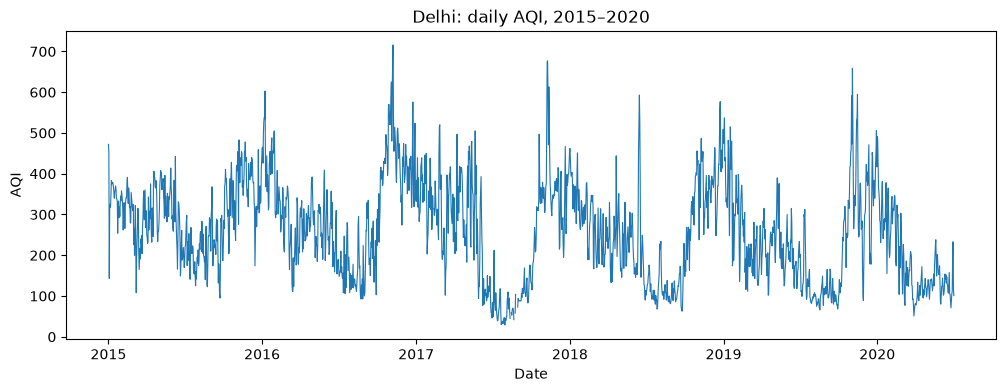

In [8]:
delhi = df[df["City"] == "Delhi"]           # keep only Delhi's rows

plt.figure(figsize=(12, 4))                 # width, height in inches
plt.plot(delhi["Date"], delhi["AQI"], linewidth=0.8)
plt.title("Delhi: daily AQI, 2015–2020")
plt.xlabel("Date")
plt.ylabel("AQI")
plt.show()


### Exercise 8.1
Make the same chart for a **different city** of your choice (try Mumbai, Bengaluru or Chennai). Then compare it with Delhi.

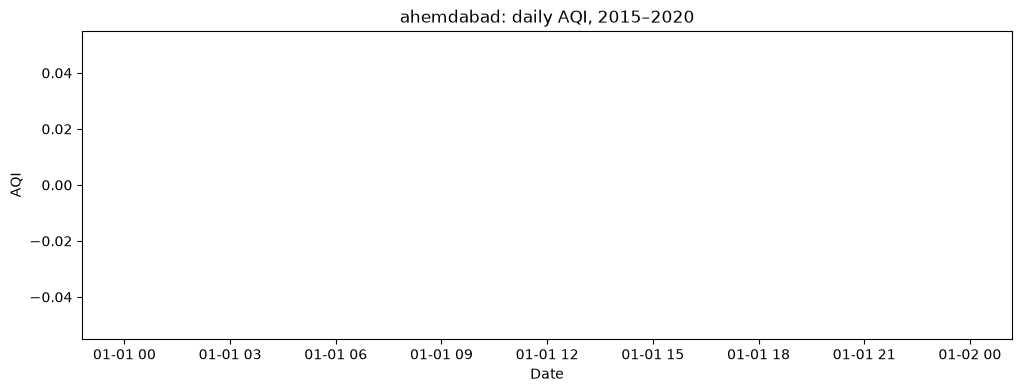

In [9]:
# Your code
ahemdabad = df[df["City"] == "Ahemdabad"]           # keep only Delhi's rows

plt.figure(figsize=(12, 4))                 # width, height in inches
plt.plot(ahemdabad["Date"], ahemdabad["AQI"], linewidth=0.8)
plt.title("ahemdabad: daily AQI, 2015–2020")
plt.xlabel("Date")
plt.ylabel("AQI")
plt.show()

**Your answer:**
1. What pattern repeats every year in Delhi? In which months is air quality worst?
2. How does your chosen city compare with Delhi?
3. Can you see anything unusual in early 2020?

>

## Wrap-up

Write your **3 most important observations** about this dataset. These will become the starting point for your final report.

1.
2.
3.

**Next lesson (02 · Cleaning):** deciding which cities and years to keep, what to do with missing values, and saving a clean dataset.

When you're done, tell Claude **"lesson 1 done"** and your notebook will be reviewed like a senior data scientist would review it.